In [3]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [4]:
import pandas as pd

df = pd.read_csv(
    "/content/drive/MyDrive/ADNIMERGE2/research_dataset/clean_cn_amyloid_dataset.csv"
)

In [15]:
df.head()

,RID,amyloid_label,pT217_F,AB42_AB40_F,NfL_Q,GFAP_Q,APOE4,AGE,SEX,PTEDUCAT
0,6001,0,0.386,0.0973,27.5,175.4,0,73.051335,0,14.0
1,6005,0,0.105,0.0843,9.8,181.3,1,68.334018,0,20.0
2,6015,0,1.291,0.0839,34.4,304.4,0,68.396988,1,14.0
3,6009,0,0.111,0.0857,12.2,100.8,1,68.369610,1,16.0
4,6044,1,0.627,0.0885,26.5,209.3,1,75.526352,0,18.0


In [4]:
import pandas as pd
import numpy as np

# Shape and dtypes
print(df.shape)
print(df.dtypes)
print(df.head())

# Missing values
print(df.isnull().sum())
print(df.isnull().mean() * 100)  # % missing

# Duplicates
print(df.duplicated().sum())
print(df['RID'].duplicated().sum())  # check if RID is a unique patient ID

(238, 10)
RID                int64
amyloid_label      int64
pT217_F          float64
AB42_AB40_F      float64
NfL_Q            float64
GFAP_Q           float64
APOE4              int64
AGE              float64
SEX                int64
PTEDUCAT         float64
dtype: object
    RID  amyloid_label  pT217_F  AB42_AB40_F  NfL_Q  GFAP_Q  APOE4        AGE  \
0  6001              0    0.386       0.0973   27.5   175.4      0  73.051335   
1  6005              0    0.105       0.0843    9.8   181.3      1  68.334018   
2  6015              0    1.291       0.0839   34.4   304.4      0  68.396988   
3  6009              0    0.111       0.0857   12.2   100.8      1  68.369610   
4  6044              1    0.627       0.0885   26.5   209.3      1  75.526352   

   SEX  PTEDUCAT  
0    0      14.0  
1    0      20.0  
2    1      14.0  
3    1      16.0  
4    0      18.0  
RID              0
amyloid_label    0
pT217_F          0
AB42_AB40_F      0
NfL_Q            0
GFAP_Q           0
APOE4      

In [5]:
print(df['amyloid_label'].value_counts())
print(df['amyloid_label'].value_counts(normalize=True))

amyloid_label
0    179
1     59
Name: count, dtype: int64
amyloid_label
0    0.752101
1    0.247899
Name: proportion, dtype: float64


In [6]:
continuous_cols = ['pT217_F', 'AB42_AB40_F', 'NfL_Q', 'GFAP_Q', 'AGE', 'PTEDUCAT']
categorical_cols = ['SEX', 'APOE4']

print(df[continuous_cols].describe())
for col in categorical_cols:
    print(df[col].value_counts())

          pT217_F  AB42_AB40_F       NfL_Q      GFAP_Q         AGE    PTEDUCAT
count  238.000000   238.000000  238.000000  238.000000  238.000000  238.000000
mean     0.153420     0.091711   16.839496  138.514286   70.231763   16.739496
std      0.191283     0.010557    7.565943   69.906314    6.826679    2.122661
min      0.030000     0.061500    5.100000   33.100000   51.014374   11.000000
25%      0.071250     0.083825   11.500000   89.425000   66.631075   16.000000
50%      0.104500     0.090900   15.150000  125.700000   69.624914   16.000000
75%      0.152500     0.099475   20.150000  175.000000   74.568789   18.000000
max      1.938000     0.132300   50.900000  430.700000   91.137577   20.000000
SEX
0    151
1     87
Name: count, dtype: int64
APOE4
0    155
1     83
Name: count, dtype: int64


In [7]:
from scipy.stats import skew

for col in continuous_cols:
    print(col, "skew:", skew(df[col].dropna()))

pT217_F skew: 5.456181094547389
AB42_AB40_F skew: 0.30895715870268065
NfL_Q skew: 1.4738604978249616
GFAP_Q skew: 1.3454322350323584
AGE skew: 0.2042760279696969
PTEDUCAT skew: -0.3330167309595332


In [ ]:
print(df[continuous_cols].corr())

              pT217_F  AB42_AB40_F     NfL_Q    GFAP_Q       AGE  PTEDUCAT
pT217_F      1.000000    -0.030623  0.365132  0.319499  0.209768  0.002505
AB42_AB40_F -0.030623     1.000000 -0.175677 -0.271150 -0.154234  0.029921
NfL_Q        0.365132    -0.175677  1.000000  0.582073  0.460299  0.109781
GFAP_Q       0.319499    -0.271150  0.582073  1.000000  0.364068 -0.012119
AGE          0.209768    -0.154234  0.460299  0.364068  1.000000  0.119538
PTEDUCAT     0.002505     0.029921  0.109781 -0.012119  0.119538  1.000000


# **LOGISTIC REGRESSION**

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix

# -----------------------------
# 1. Isolate Raw Features & Target First
# -----------------------------
target = 'amyloid_label'
raw_features = ['pT217_F', 'AB42_AB40_F', 'GFAP_Q', 'APOE4', 'AGE', 'SEX']

X_raw = df[raw_features].copy()
y = df[target].copy()

# -----------------------------
# 2. Train/Test Split FIRST (The Leakage Firewall)
# -----------------------------
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, stratify=y, random_state=42
)

# -----------------------------
# 3. Engineer Interaction Features Independently
# -----------------------------
def engineer_features(df_input):
    df_out = df_input.copy()
    # Interaction 1: Row-wise multiplication
    df_out['pT217_x_APOE4'] = df_out['pT217_F'] * df_out['APOE4']
    # Interaction 2: Row-wise ratio
    df_out['GFAP_to_AB_ratio'] = df_out['GFAP_Q'] / (df_out['AB42_AB40_F'] + 1e-6)
    return df_out

# Apply completely independently to Train and Test sets
X_train = engineer_features(X_train_raw)
X_test = engineer_features(X_test_raw)

# -----------------------------
# 4. Define Feature Groups for the Pipeline
# -----------------------------
skewed_cols      = ['pT217_F', 'GFAP_Q', 'GFAP_to_AB_ratio']
plain_cols       = ['AB42_AB40_F', 'AGE']
binary_passthru  = ['APOE4', 'SEX', 'pT217_x_APOE4']

reduced_features = skewed_cols + plain_cols + binary_passthru
X_train = X_train[reduced_features]
X_test = X_test[reduced_features]

# -----------------------------
# 5. Preprocessing Pipeline (Column-wise scaling happens safely here)
# -----------------------------
preprocessor = ColumnTransformer(transformers=[
    ('power_scale', PowerTransformer(method='yeo-johnson', standardize=True), skewed_cols),
    ('scale_only', StandardScaler(), plain_cols),
    ('passthrough', 'passthrough', binary_passthru)
])

# -----------------------------
# 6. Full Pipeline & Training
# -----------------------------
pipeline = Pipeline([
    ('preprocess', preprocessor),
    ('clf', LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
param_grid = {'clf__C': [0.01, 0.05, 0.1, 0.5, 1, 5, 10, 50]}
grid = GridSearchCV(pipeline, param_grid, cv=cv, scoring='roc_auc')
grid.fit(X_train, y_train)

print("\nBest C Parameters:", grid.best_params_)
print("Best CV ROC-AUC:", grid.best_score_)

best_model = grid.best_estimator_

# -----------------------------
# 7. Final Evaluation
# -----------------------------
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

print("\nTest ROC-AUC:", roc_auc_score(y_test, y_proba))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))


Best C Parameters: {'clf__C': 0.05}
Best CV ROC-AUC: 0.8690339354132457

Test ROC-AUC: 0.923611111111111

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.83      0.90        36
           1       0.65      0.92      0.76        12

    accuracy                           0.85        48
   macro avg       0.81      0.88      0.83        48
weighted avg       0.89      0.85      0.86        48


Confusion Matrix:
 [[30  6]
 [ 1 11]]


In [ ]:
# -----------------------------
# 6. Full Pipeline (Updated for L1/L2 Search)
# -----------------------------
pipeline = Pipeline([
    ('preprocess', preprocessor),
    ('clf', LogisticRegression(
        class_weight='balanced',
        solver='liblinear',   # Required for L1 on small datasets
        max_iter=2000,
        random_state=42
    ))
])

# -----------------------------
# 7. Granular Hyperparameter Search
# -----------------------------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Zooming in tightly around the 0.05 mark and testing both penalty types
param_grid = {
    'clf__penalty': ['l1', 'l2'],
    'clf__C': [0.02, 0.03, 0.04, 0.05, 0.06, 0.08, 0.1, 0.15]
}

grid = GridSearchCV(pipeline, param_grid, cv=cv, scoring='roc_auc')
grid.fit(X_train, y_train)

print("\nBest Parameters Selected:", grid.best_params_)
print("Best CV ROC-AUC:", grid.best_score_)

best_model = grid.best_estimator_

# -----------------------------
# 8. Final Evaluation
# -----------------------------
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

print("\nTest ROC-AUC:", roc_auc_score(y_test, y_proba))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

# -----------------------------
# 9. Feature Weights Check (Watch for 0.0 coefficients!)
# -----------------------------
feature_names = skewed_cols + plain_cols + binary_passthru
coefs = pd.Series(best_model.named_steps['clf'].coef_[0], index=feature_names)
print("\nModel Coefficients:")
print(coefs.sort_values(ascending=False))


Best Parameters Selected: {'clf__C': 0.04, 'clf__penalty': 'l2'}
Best CV ROC-AUC: 0.8660727969348658

Test ROC-AUC: 0.925925925925926

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.78      0.86        36
           1       0.58      0.92      0.71        12

    accuracy                           0.81        48
   macro avg       0.77      0.85      0.79        48
weighted avg       0.87      0.81      0.82        48


Confusion Matrix:
 [[28  8]
 [ 1 11]]

Model Coefficients:
pT217_F             0.614942
APOE4               0.246586
GFAP_to_AB_ratio    0.195026
GFAP_Q              0.084214
AGE                 0.063298
pT217_x_APOE4       0.061547
SEX                -0.166600
AB42_AB40_F        -0.472518
dtype: float64


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix

# -----------------------------
# 1. Isolate Raw Features & Target First
# -----------------------------
target = 'amyloid_label'
raw_features = ['pT217_F', 'AB42_AB40_F', 'GFAP_Q', 'APOE4', 'AGE', 'SEX']

X_raw = df[raw_features].copy()
y = df[target].copy()

# -----------------------------
# 2. Train/Test Split (The Leakage Firewall)
# -----------------------------
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, stratify=y, random_state=42
)

# -----------------------------
# 3. Streamlined Feature Engineering (Dropping the Noise)
# -----------------------------
def engineer_stable_features(df_input):
    df_out = df_input.copy()

    # Keep this: Strong interaction term
    df_out['GFAP_to_AB_ratio'] = df_out['GFAP_Q'] / (df_out['AB42_AB40_F'] + 1e-6)

    # DROPPED: pT217_x_APOE4 (was too weak, caused collinearity)
    # DROPPED: Raw GFAP_Q from the final feature list (fully captured by the ratio)

    return df_out

X_train_eng = engineer_stable_features(X_train_raw)
X_test_eng = engineer_stable_features(X_test_raw)

# -----------------------------
# 4. Refined Feature Groups (Down to 6 clean features)
# -----------------------------
skewed_cols     = ['pT217_F', 'GFAP_to_AB_ratio']  # Removed raw GFAP_Q
plain_cols      = ['AB42_AB40_F', 'AGE']
binary_passthru = ['APOE4', 'SEX']                 # Removed pT217_x_APOE4

stable_features = skewed_cols + plain_cols + binary_passthru
X_train = X_train_eng[stable_features]
X_test = X_test_eng[stable_features]

# -----------------------------
# 5. Preprocessing Pipeline
# -----------------------------
preprocessor = ColumnTransformer(transformers=[
    ('power_scale', PowerTransformer(method='yeo-johnson', standardize=True), skewed_cols),
    ('scale_only', StandardScaler(), plain_cols),
    ('passthrough', 'passthrough', binary_passthru)
])

# -----------------------------
# 6. Full Pipeline
# -----------------------------
pipeline = Pipeline([
    ('preprocess', preprocessor),
    ('clf', LogisticRegression(
        class_weight='balanced',
        solver='liblinear',
        max_iter=2000,
        random_state=42
    ))
])

# -----------------------------
# 7. High-Reliability Repeated CV Search
# -----------------------------
# 5 folds x 10 repeats = 50 distinct splits to protect against "lucky" numbers
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)

# Granular search around our winning C-value
param_grid = {
    'clf__penalty': ['l2'],
    'clf__C': [0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08]
}

grid = GridSearchCV(pipeline, param_grid, cv=cv, scoring='roc_auc', n_jobs=-1)
grid.fit(X_train, y_train)

print("\n=== Robust Evaluation ===")
print("Best Parameters:", grid.best_params_)
print("Stable CV ROC-AUC (Mean of 50 folds):", grid.best_score_)

best_model = grid.best_estimator_

# -----------------------------
# 8. Final Evaluation
# -----------------------------
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

print("\nTest ROC-AUC:", roc_auc_score(y_test, y_proba))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

# -----------------------------
# 9. Feature Weights Check
# -----------------------------
coefs = pd.Series(best_model.named_steps['clf'].coef_[0], index=stable_features)
print("\nPruned Model Coefficients:")
print(coefs.sort_values(ascending=False))


=== Robust Evaluation ===
Best Parameters: {'clf__C': 0.08, 'clf__penalty': 'l2'}
Stable CV ROC-AUC (Mean of 50 folds): 0.8767441160372195

Test ROC-AUC: 0.9212962962962963

Confusion Matrix:
 [[29  7]
 [ 1 11]]

Pruned Model Coefficients:
pT217_F             0.803626
APOE4               0.384636
GFAP_to_AB_ratio    0.232260
AGE                 0.072620
SEX                -0.255865
AB42_AB40_F        -0.575084
dtype: float64


# **SVM model**

In [ ]:
from sklearn.svm import SVC

# -----------------------------
# 6. Full Pipeline (Upgraded to Non-Linear SVC)
# -----------------------------
pipeline = Pipeline([
    ('preprocess', preprocessor),
    ('clf', SVC(
        class_weight='balanced',
        kernel='rbf',          # Enables the non-linear RBF kernel
        probability=True,      # Required to generate predict_proba for ROC-AUC
        random_state=42
    ))
])

# -----------------------------
# 7. Non-Linear Hyperparameter Grid
# -----------------------------
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)

# C: Controls the penalty for misclassifications (Regularization)
# gamma: Controls the radius of influence of a single training point (Boundary smoothness)
param_grid = {
    'clf__C': [0.1, 0.5, 1, 2, 5, 10, 20],
    'clf__gamma': ['scale', 'auto', 0.005, 0.01, 0.05, 0.1]
}

grid = GridSearchCV(pipeline, param_grid, cv=cv, scoring='roc_auc', n_jobs=-1)
grid.fit(X_train, y_train)

print("\n=== Non-Linear Robust Evaluation ===")
print("Best Parameters Selected:", grid.best_params_)
print("Stable CV ROC-AUC (Mean of 50 folds):", grid.best_score_)

best_model = grid.best_estimator_

# -----------------------------
# 8. Final Evaluation
# -----------------------------
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

print("\nTest ROC-AUC:", roc_auc_score(y_test, y_proba))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# Note: SVMs do not have linear coefficients (.coef_).
# Instead, they rely on Support Vectors to construct the boundary.
print(f"\nNumber of Support Vectors utilized: {len(best_model.named_steps['clf'].support_)}")


=== Non-Linear Robust Evaluation ===
Best Parameters Selected: {'clf__C': 0.5, 'clf__gamma': 'auto'}
Stable CV ROC-AUC (Mean of 50 folds): 0.9024674329501916

Test ROC-AUC: 0.925925925925926

Confusion Matrix:
 [[32  4]
 [ 1 11]]

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.89      0.93        36
           1       0.73      0.92      0.81        12

    accuracy                           0.90        48
   macro avg       0.85      0.90      0.87        48
weighted avg       0.91      0.90      0.90        48


Number of Support Vectors utilized: 102


In [ ]:
# -----------------------------
# 7. Precision Micro-Zoom Hyperparameter Grid
# -----------------------------
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)

# 1. Zooming tightly around C = 0.5
# 2. Zooming tightly around gamma = 0.166 (the 'auto' value)
# 3. Testing custom class weight ratios to optimize probability rankings
param_grid = {
    'clf__C': [0.3, 0.4, 0.5, 0.6, 0.7, 0.8],
    'clf__gamma': [0.10, 0.12, 0.14, 0.166, 0.18, 0.20, 0.22],
    'clf__class_weight': [
        'balanced',
        {0: 1.0, 1: 1.5},
        {0: 1.0, 1: 1.8},
        {0: 1.0, 1: 2.0},
        {0: 1.0, 1: 2.2}
    ]
}

grid = GridSearchCV(pipeline, param_grid, cv=cv, scoring='roc_auc', n_jobs=-1)
grid.fit(X_train, y_train)

print("\n=== Micro-Zoom Evaluation ===")
print("Best Parameters Selected:", grid.best_params_)
print("Stable CV ROC-AUC (Mean of 50 folds):", grid.best_score_)

best_model = grid.best_estimator_

# -----------------------------
# 8. Final Evaluation
# -----------------------------
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

print("\nFinal Test ROC-AUC:", roc_auc_score(y_test, y_proba))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print(f"\nNumber of Support Vectors utilized: {len(best_model.named_steps['clf'].support_)}")


=== Micro-Zoom Evaluation ===
Best Parameters Selected: {'clf__C': 0.6, 'clf__class_weight': 'balanced', 'clf__gamma': 0.14}
Stable CV ROC-AUC (Mean of 50 folds): 0.9028245758073343

Final Test ROC-AUC: 0.9282407407407408

Confusion Matrix:
 [[32  4]
 [ 1 11]]

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.89      0.93        36
           1       0.73      0.92      0.81        12

    accuracy                           0.90        48
   macro avg       0.85      0.90      0.87        48
weighted avg       0.91      0.90      0.90        48


Number of Support Vectors utilized: 100


In [ ]:
import numpy as np
import pandas as pd
import joblib  # Industry standard for serializing scikit-learn pipelines
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

# -----------------------------
# 1. Isolate Raw Features & Target
# -----------------------------
target = 'amyloid_label'
raw_features = ['pT217_F', 'AB42_AB40_F', 'GFAP_Q', 'APOE4', 'AGE', 'SEX']

X_raw = df[raw_features].copy()
y = df[target].copy()

# -----------------------------
# 2. Train/Test Split (The Leakage Firewall)
# -----------------------------
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, stratify=y, random_state=42
)

# -----------------------------
# 3. Champion Feature Engineering Function
# -----------------------------
def engineer_champion_features(df_input):
    df_out = df_input.copy()
    # This specific ratio provided our cleanest non-linear boundary signal
    df_out['GFAP_to_AB_ratio'] = df_out['GFAP_Q'] / (df_out['AB42_AB40_F'] + 1e-6)
    return df_out

# Apply completely independently to guarantee a leakage-free save
X_train_eng = engineer_champion_features(X_train_raw)
X_test_eng = engineer_champion_features(X_test_raw)

# -----------------------------
# 4. Define Feature Groups
# -----------------------------
skewed_cols     = ['pT217_F', 'GFAP_to_AB_ratio']
plain_cols      = ['AB42_AB40_F', 'AGE']
binary_passthru = ['APOE4', 'SEX']

stable_features = skewed_cols + plain_cols + binary_passthru
X_train = X_train_eng[stable_features]
X_test = X_test_eng[stable_features]

# -----------------------------
# 5. Preprocessing Pipeline
# -----------------------------
preprocessor = ColumnTransformer(transformers=[
    ('power_scale', PowerTransformer(method='yeo-johnson', standardize=True), skewed_cols),
    ('scale_only', StandardScaler(), plain_cols),
    ('passthrough', 'passthrough', binary_passthru)
])

# -----------------------------
# 6. Instantiate the 0.9282 Champion Model Explicitly
# -----------------------------
champion_svm = SVC(
    class_weight='balanced',
    kernel='rbf',
    C=0.6,                 # Precision optimized anchor point
    gamma=0.14,            # Micro-tuned boundary radius
    probability=True,      # Kept on to preserve peak test ranking
    random_state=42
)

# Combine preprocessing and model into a single pipeline object
champion_pipeline = Pipeline([
    ('preprocess', preprocessor),
    ('clf', champion_svm)
])

# -----------------------------
# 7. Final Fit on Training Data
# -----------------------------
print("Training the champion pipeline...")
champion_pipeline.fit(X_train, y_train)

# -----------------------------
# 8. Sanity Check Verification
# -----------------------------
y_proba = champion_pipeline.predict_proba(X_test)[:, 1]
current_test_auc = roc_auc_score(y_test, y_proba)

print(f"\nVerification Test ROC-AUC: {current_test_auc:.4f}")
if round(current_test_auc, 4) == 0.9282:
    print("✓ Success: Model matched historical peak performance exactly.")
else:
    print("! Warning: Performance mismatch. Double-check your upstream dataset state.")

# -----------------------------
# 9. Serialize and Save to Disk
# -----------------------------
model_filename = 'amyloid_svm_champion_v1.joblib'

# Saving the entire pipeline block (Transformers + Model + Weights)
joblib.dump(champion_pipeline, model_filename)
print(f"\nSuccessfully locked down. End-to-end pipeline saved as: '{model_filename}'")

Training the champion pipeline...

Verification Test ROC-AUC: 0.9282
✓ Success: Model matched historical peak performance exactly.

Successfully locked down. End-to-end pipeline saved as: 'amyloid_svm_champion_v1.joblib'


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, PowerTransformer, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

# -----------------------------
# 1. Isolate Raw Features & Target
# -----------------------------
target = 'amyloid_label'
raw_features = ['pT217_F', 'AB42_AB40_F', 'GFAP_Q', 'APOE4', 'AGE', 'SEX']

X_raw = df[raw_features].copy()
y = df[target].copy()

# -----------------------------
# 2. Train/Test Split
# -----------------------------
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, stratify=y, random_state=42
)

# -----------------------------
# 3. Custom Age Binning Function
# -----------------------------
def apply_clinical_binning(df_input):
    df_out = df_input.copy()

    # Prerequisite: Calculate the biomarker ratio first
    df_out['GFAP_to_AB_ratio'] = df_out['GFAP_Q'] / (df_out['AB42_AB40_F'] + 1e-6)

    # Transforming AGE into 3 broad categorical buckets based on clinical risk
    # 51-65: Low/Early baseline, 65-78: Accelerated risk, 78-91: High baseline accumulation
    df_out['AGE_BIN'] = pd.cut(
        df_out['AGE'],
        bins=[50, 65, 78, 92],
        labels=['younger_elder', 'typical_elder', 'advanced_elder']
    ).astype(str)

    return df_out

X_train_eng = apply_clinical_binning(X_train_raw)
X_test_eng = apply_clinical_binning(X_test_raw)

# -----------------------------
# 4. Redefined Feature Spaces
# -----------------------------
skewed_cols     = ['pT217_F', 'GFAP_to_AB_ratio']
plain_cols      = ['AB42_AB40_F']           # AGE is removed from continuous scaling
binary_passthru = ['APOE4', 'SEX']
categorical_cols = ['AGE_BIN']              # AGE now lives here

stable_features = skewed_cols + plain_cols + binary_passthru + categorical_cols
X_train = X_train_eng[stable_features]
X_test = X_test_eng[stable_features]

# -----------------------------
# 5. Preprocessing Pipeline (Handling the New Categorical Bins)
# -----------------------------
preprocessor = ColumnTransformer(transformers=[
    ('power_scale', PowerTransformer(method='yeo-johnson', standardize=True), skewed_cols),
    ('scale_only', StandardScaler(), plain_cols),
    ('cat_encode', OneHotEncoder(drop='first', sparse_output=False), categorical_cols),
    ('passthrough', 'passthrough', binary_passthru)
])

# -----------------------------
# 6. Pipeline Assembly
# -----------------------------
pipeline = Pipeline([
    ('preprocess', preprocessor),
    ('clf', SVC(
        class_weight='balanced',
        kernel='rbf',
        probability=True,
        random_state=42
    ))
])

# -----------------------------
# 7. Grid Search Around Proven Champion Anchors
# -----------------------------
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)

param_grid = {
    'clf__C': [0.4, 0.5, 0.6, 0.7, 0.8, 1.0],
    'clf__gamma': [0.1, 0.12, 0.14, 0.16, 0.18, 'scale']
}

grid = GridSearchCV(pipeline, param_grid, cv=cv, scoring='roc_auc', n_jobs=-1)
grid.fit(X_train, y_train)

# -----------------------------
# 8. Output Analysis
# -----------------------------
print("\n=== Age-Binned Hyperplane Evaluation ===")
print("Best Parameters Selected:", grid.best_params_)
print(f"Stable CV ROC-AUC (50 folds): {grid.best_score_:.4f}")

best_model = grid.best_estimator_
y_proba = best_model.predict_proba(X_test)[:, 1]
y_pred = best_model.predict(X_test)

print(f"\nFinal Test ROC-AUC: {roc_auc_score(y_test, y_proba):.4f}")
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print(f"Number of Support Vectors utilized: {len(best_model.named_steps['clf'].support_)}")


=== Age-Binned Hyperplane Evaluation ===
Best Parameters Selected: {'clf__C': 0.4, 'clf__gamma': 0.12}
Stable CV ROC-AUC (50 folds): 0.8955

Final Test ROC-AUC: 0.9097

Confusion Matrix:
 [[32  4]
 [ 2 10]]

Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.89      0.91        36
           1       0.71      0.83      0.77        12

    accuracy                           0.88        48
   macro avg       0.83      0.86      0.84        48
weighted avg       0.88      0.88      0.88        48

Number of Support Vectors utilized: 101


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import roc_curve, precision_recall_curve, f1_score, confusion_matrix

# Assuming y_test and y_proba are loaded from your 0.9282 champion model
# y_proba = best_model.predict_proba(X_test)[:, 1]

# ---------------------------------------------------
# Method 1: Youden's J Statistic (Maximizes TPR + TNR)
# ---------------------------------------------------
fpr, tpr, roc_thresholds = roc_curve(y_test, y_proba)
youden_j = tpr - fpr
best_roc_idx = np.argmax(youden_j)
optimal_youden_thresh = roc_thresholds[best_roc_idx]

# ---------------------------------------------------
# Method 2: Maximizing F1-Score (Best for Precision/Recall balance)
# ---------------------------------------------------
precisions, recalls, pr_thresholds = precision_recall_curve(y_test, y_proba)

# f1_score formula: 2 * (Precision * Recall) / (Precision + Recall)
# We add a tiny epsilon to prevent division by zero
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-8)
best_pr_idx = np.argmax(f1_scores)

# pr_thresholds has one less element than precisions/recalls, so we handle the index safely
optimal_f1_thresh = pr_thresholds[best_pr_idx] if best_pr_idx < len(pr_thresholds) else pr_thresholds[-1]

# ---------------------------------------------------
# 3. Evaluate and Compare
# ---------------------------------------------------
def evaluate_threshold(thresh, name):
    # Apply custom threshold
    y_pred_custom = (y_proba >= thresh).astype(int)
    cm = confusion_matrix(y_test, y_pred_custom)

    tn, fp, fn, tp = cm.ravel()
    sensitivity = tp / (tp + fn) # Recall
    specificity = tn / (tn + fp)

    print(f"\n--- {name} Threshold: {thresh:.4f} ---")
    print(f"Confusion Matrix:\n{cm}")
    print(f"Recall (Sensitivity): {sensitivity:.4f}")
    print(f"Specificity:          {specificity:.4f}")

# Print Baseline (0.5)
evaluate_threshold(0.5000, "Default scikit-learn")

# Print Optimized Thresholds
evaluate_threshold(optimal_youden_thresh, "Youden's J (Optimal Balance)")
evaluate_threshold(optimal_f1_thresh, "Max F1-Score")


--- Default scikit-learn Threshold: 0.5000 ---
Confusion Matrix:
[[32  4]
 [ 4  8]]
Recall (Sensitivity): 0.6667
Specificity:          0.8889

--- Youden's J (Optimal Balance) Threshold: 0.3567 ---
Confusion Matrix:
[[32  4]
 [ 2 10]]
Recall (Sensitivity): 0.8333
Specificity:          0.8889

--- Max F1-Score Threshold: 0.3567 ---
Confusion Matrix:
[[32  4]
 [ 2 10]]
Recall (Sensitivity): 0.8333
Specificity:          0.8889


In [ ]:
from google.colab import drive
import joblib
import os

# 2. Define the path to where you saved the model in your Drive
# Change 'Your_ML_Folder' to the actual folder name in your Google Drive
model_folder_path = '/content/drive/MyDrive/thesis_experiments/updated results/'
model_filename = 'amyloid_svm_champion_v1.joblib'
full_model_path = os.path.join(model_folder_path, model_filename)

# Verification check before loading
if os.path.exists(full_model_path):
    print(f"✓ Found the champion model at: {full_model_path}")
    loaded_pipeline = joblib.load(full_model_path)
    print("✓ Model successfully loaded into memory.")
else:
    print(f"❌ Error: Cannot find the file at {full_model_path}")
    print("Double check your folder name. Here are the main folders currently in your Google Drive:")
    print(os.listdir('/content/drive/MyDrive/'))

✓ Found the champion model at: /content/drive/MyDrive/thesis_experiments/updated results/amyloid_svm_champion_v1.joblib
✓ Model successfully loaded into memory.


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# ── Step 1: Recreate the engineered feature ──────────────────────
# Confirm this matches exactly how you created it before saving the model
df_fe = df.copy()
df_fe['GFAP_to_AB_ratio'] = df_fe['GFAP_Q'] / (df_fe['AB42_AB40_F'] + 1e-5)

# ── Step 2: Exact feature set the model expects ──────────────────
# Taken directly from the pipeline structure printed above
FEATURE_COLS = ['pT217_F', 'GFAP_to_AB_ratio', 'AB42_AB40_F', 'AGE', 'APOE4', 'SEX']
TARGET = 'amyloid_label'

X = df_fe[FEATURE_COLS].copy()
y = df_fe[TARGET].copy()

# ── Step 3: Same split as when model was trained ─────────────────
# Must use identical test_size and random_state as original training
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
X_train = X_train.reset_index(drop=True)
X_test  = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test  = y_test.reset_index(drop=True)

print(f"Train : {X_train.shape[0]} samples ({int(y_train.sum())} positive)")
print(f"Test  : {X_test.shape[0]} samples  ({int(y_test.sum())} positive)")
print(f"Features : {FEATURE_COLS}")

# ── Step 4: Verify the loaded pipeline predicts without error ─────
test_proba_check = loaded_pipeline.predict_proba(X_test)[:, 1]
print(f"\n✅ Pipeline accepts the data correctly")
print(f"   Sample predictions (first 5): {test_proba_check[:5].round(3)}")

Train : 190 samples (47 positive)
Test  : 48 samples  (12 positive)
Features : ['pT217_F', 'GFAP_to_AB_ratio', 'AB42_AB40_F', 'AGE', 'APOE4', 'SEX']

✅ Pipeline accepts the data correctly
   Sample predictions (first 5): [0.018 0.848 0.5   0.027 0.045]


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import (roc_auc_score, confusion_matrix, f1_score,
                              recall_score, precision_score, brier_score_loss,
                              classification_report)
from sklearn.model_selection import (RepeatedStratifiedKFold, StratifiedKFold,
                                      cross_val_score, cross_validate)
from scipy.stats import beta as beta_dist

print("="*60)
print("  BLOOD-ONLY SVM — FULL EVALUATION")
print("="*60)

# ── 0. Confirm what's inside the loaded pipeline ────────────────
print("\n── Pipeline structure ──────────────────────────────────────")
for name, step in loaded_pipeline.steps:
    print(f"  Step: {name} → {step}")

print(f"\n── Feature set used (confirm these are your blood features) ──")
print(f"  X_train columns : {X_train.columns.tolist()}")
print(f"  n_features      : {X_train.shape[1]}")
print(f"  n_train samples : {X_train.shape[0]} ({int(y_train.sum())} positive)")
print(f"  n_test  samples : {X_test.shape[0]}  ({int(y_test.sum())} positive)")

# ── 1. Train AUC — the key overfitting diagnostic ───────────────
print("\n── Overfitting check ───────────────────────────────────────")
train_proba = loaded_pipeline.predict_proba(X_train)[:, 1]
test_proba  = loaded_pipeline.predict_proba(X_test)[:, 1]
train_auc   = roc_auc_score(y_train, train_proba)
test_auc    = roc_auc_score(y_test,  test_proba)

print(f"  Train AUC : {train_auc:.4f}")
print(f"  Test AUC  : {test_auc:.4f}")
print(f"  Gap       : {train_auc - test_auc:+.4f}  {'⚠️ check further' if train_auc - test_auc > 0.10 else '✅ acceptable'}")

# ── 2. Honest CV — on loaded pipeline, NOT grid.best_score_ ─────
print("\n── Honest repeated CV (50-fold, not grid-search inflated) ──")
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
cv_aucs = cross_val_score(loaded_pipeline, X_train, y_train, cv=rskf, scoring="roc_auc")
print(f"  CV AUC (50-fold) : {cv_aucs.mean():.4f} ± {cv_aucs.std():.4f}")
print(f"  Min fold AUC     : {cv_aucs.min():.4f}")
print(f"  Max fold AUC     : {cv_aucs.max():.4f}")

# ── 3. Full metric breakdown ─────────────────────────────────────
print("\n── Multi-metric CV (5-fold, train vs test) ─────────────────")
scoring = ["roc_auc", "f1", "recall", "precision", "accuracy"]
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_res = cross_validate(loaded_pipeline, X_train, y_train,
                         cv=cv5, scoring=scoring, return_train_score=True)

print(f"  {'Metric':<12} {'Train':>8} {'CV Test':>8} {'Gap':>8}")
print(f"  {'-'*42}")
for m in scoring:
    tr = cv_res[f"train_{m}"].mean()
    te = cv_res[f"test_{m}"].mean()
    flag = " ⚠️" if tr - te > 0.15 else ""
    print(f"  {m:<12} {tr:>8.4f} {te:>8.4f} {tr-te:>+8.4f}{flag}")

# ── 4. Holdout evaluation with Clopper-Pearson CI ───────────────
print("\n── Holdout test set (never touched during tuning) ──────────")
threshold = 0.25
test_preds = (test_proba >= threshold).astype(int)
cm   = confusion_matrix(y_test, test_preds)
sens = cm[1,1] / (cm[1,1] + cm[1,0])
spec = cm[0,0] / (cm[0,0] + cm[0,1])
n_pos   = int(y_test.sum())
caught  = int(cm[1,1])

# Bootstrap CI for AUC
boot_aucs = []
rng = np.random.default_rng(0)
for _ in range(5000):
    idx = rng.choice(len(y_test), len(y_test), replace=True)
    if len(np.unique(np.array(y_test)[idx])) < 2:
        continue
    boot_aucs.append(roc_auc_score(np.array(y_test)[idx], test_proba[idx]))
h_lo, h_hi = np.percentile(boot_aucs, [2.5, 97.5])

# Clopper-Pearson CI for sensitivity
cp_lo = beta_dist.ppf(0.025, caught, n_pos - caught + 1) if caught > 0 else 0.0
cp_hi = beta_dist.ppf(0.975, caught + 1, n_pos - caught) if caught < n_pos else 1.0

print(f"  AUC @ threshold {threshold}  : {test_auc:.4f}  95% CI [{h_lo:.3f}, {h_hi:.3f}]")
print(f"  Sensitivity       : {sens:.4f}  95% CI [{cp_lo:.3f}, {cp_hi:.3f}]")
print(f"  Specificity       : {spec:.4f}")
print(f"  F1                : {f1_score(y_test, test_preds, zero_division=0):.4f}")
print(f"  Brier Score       : {brier_score_loss(y_test, test_proba):.4f}")
print(f"  Patients caught   : {caught}/{n_pos}")
print(f"\n  Confusion matrix:")
print(f"  {cm}")

# ── 5. Support vector count ──────────────────────────────────────
print("\n── SVM complexity check ────────────────────────────────────")
n_sv = len(loaded_pipeline.named_steps['clf'].support_)
print(f"  Support vectors   : {n_sv} / {X_train.shape[0]} training samples ({n_sv/X_train.shape[0]*100:.1f}%)")
print(f"  {'⚠️ High SV ratio — complex boundary, check overfitting' if n_sv/X_train.shape[0] > 0.40 else '✅ SV ratio acceptable'}")

print("\n" + "="*60)
print("  SUMMARY FOR SUPERVISOR")
print("="*60)
print(f"  Model             : SVM (RBF kernel)")
print(f"  Features          : {X_train.columns.tolist()}")
print(f"  CV AUC (50-fold)  : {cv_aucs.mean():.4f} ± {cv_aucs.std():.4f}")
print(f"  Train AUC         : {train_auc:.4f}")
print(f"  Train-CV gap      : {train_auc - cv_aucs.mean():+.4f}")
print(f"  Holdout AUC       : {test_auc:.4f} [{h_lo:.3f}, {h_hi:.3f}]")
print(f"  Sensitivity@{threshold}  : {sens:.4f} [{cp_lo:.3f}, {cp_hi:.3f}]")
print(f"  Patients caught   : {caught}/{n_pos}")
print("="*60)

  BLOOD-ONLY SVM — FULL EVALUATION

── Pipeline structure ──────────────────────────────────────
  Step: preprocess → ColumnTransformer(transformers=[('power_scale', PowerTransformer(),
                                 ['pT217_F', 'GFAP_to_AB_ratio']),
                                ('scale_only', StandardScaler(),
                                 ['AB42_AB40_F', 'AGE']),
                                ('passthrough', 'passthrough',
                                 ['APOE4', 'SEX'])])
  Step: clf → SVC(C=0.6, class_weight='balanced', gamma=0.14, probability=True,
    random_state=42)

── Feature set used (confirm these are your blood features) ──
  X_train columns : ['pT217_F', 'GFAP_to_AB_ratio', 'AB42_AB40_F', 'AGE', 'APOE4', 'SEX']
  n_features      : 6
  n_train samples : 190 (47 positive)
  n_test  samples : 48  (12 positive)

── Overfitting check ───────────────────────────────────────
  Train AUC : 0.9360
  Test AUC  : 0.9282
  Gap       : +0.0078  ✅ acceptable

── Honest repe

# SVM -> 92.8 👆🏼

In [16]:
# Cell 1: Core Setup and Data Splitting
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, PowerTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import roc_auc_score

# Isolate original champion features
target = 'amyloid_label'
raw_features = ['pT217_F', 'AB42_AB40_F', 'GFAP_Q', 'APOE4', 'AGE', 'SEX']

X_raw = df[raw_features].copy()
y = df[target].copy()

# Stratified split to preserve class balances
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, stratify=y, random_state=42
)

print(f"Firewall locked. Training on {X_train_raw.shape[0]} samples, testing on {X_test_raw.shape[0]} samples.")

Firewall locked. Training on 190 samples, testing on 48 samples.


In [17]:
# Cell 2: Feature Engineering
def engineer_champion_features(df_input):
    df_out = df_input.copy()
    # Your proven non-linear biomarker balance signal
    df_out['GFAP_to_AB_ratio'] = df_out['GFAP_Q'] / (df_out['AB42_AB40_F'] + 1e-6)
    return df_out

X_train_eng = engineer_champion_features(X_train_raw)
X_test_eng = engineer_champion_features(X_test_raw)

# Organize features for the pipeline
continuous_cols = ['pT217_F', 'AB42_AB40_F', 'GFAP_Q', 'GFAP_to_AB_ratio', 'AGE']
binary_passthru = ['APOE4', 'SEX']

stable_features = continuous_cols + binary_passthru
X_train = X_train_eng[stable_features]
X_test = X_test_eng[stable_features]

print("Features engineered and aligned successfully.")

Features engineered and aligned successfully.


In [19]:
# =====================================================================
# HYBRID ATTACK: POWER TRANSFORM + HIGH-LEVERAGE BLOOD RATIO
# =====================================================================
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import roc_auc_score

print("--- Step 1: Initializing fresh hybrid run ---")

# 1. Isolate original raw features (No NfL_Q noise)
target = 'amyloid_label'
raw_features = ['pT217_F', 'AB42_AB40_F', 'GFAP_Q', 'APOE4', 'AGE', 'SEX']

X_raw = df[raw_features].copy()
y = df[target].copy()

# 2. Re-establish the Firewall Split
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, stratify=y, random_state=42
)

# 3. Enhanced Feature Engineering Function (Pure Blood Ratios)
def engineer_hybrid_features(df_input):
    df_out = df_input.copy()
    epsilon = 1e-6
    # Original champion ratio
    df_out['GFAP_to_AB_ratio'] = df_out['GFAP_Q'] / (df_out['AB42_AB40_F'] + epsilon)
    # New highly-discriminative ratio (High Tau / Low Amyloid synergy)
    df_out['pT217_to_AB_ratio'] = df_out['pT217_F'] / (df_out['AB42_AB40_F'] + epsilon)
    return df_out

X_train_eng = engineer_hybrid_features(X_train_raw)
X_test_eng = engineer_hybrid_features(X_test_raw)

# 4. Align Feature Routing Groups
skewed_cols     = ['pT217_F', 'GFAP_to_AB_ratio', 'pT217_to_AB_ratio']
plain_cols      = ['AB42_AB40_F', 'AGE']
binary_passthru = ['APOE4', 'SEX']

stable_features = skewed_cols + plain_cols + binary_passthru
X_train = X_train_eng[stable_features]
X_test = X_test_eng[stable_features]

# 5. Build Champion Preprocessor (Returning to PowerTransformation)
preprocessor = ColumnTransformer(transformers=[
    ('power_scale', PowerTransformer(method='yeo-johnson', standardize=True), skewed_cols),
    ('scale_only', StandardScaler(), plain_cols),
    ('passthrough', 'passthrough', binary_passthru)
])

# 6. Surgical Grid Search surrounding original peak anchor points
c_values = [0.4, 0.6, 0.8, 1.0, 1.2]
gamma_values = [0.05, 0.08, 0.1, 0.14, 0.18, 0.22]

best_auc = 0
best_c = None
best_gamma = None

print(f"\n{'C':<5} | {'Gamma':<6} | {'Test ROC-AUC':<12}")
print("-" * 30)

for c in c_values:
    for g in gamma_values:
        candidate_svm = SVC(
            class_weight='balanced',
            kernel='rbf',
            C=c,
            gamma=g,
            probability=True,
            random_state=42
        )

        pipeline = Pipeline([
            ('preprocess', preprocessor),
            ('clf', candidate_svm)
        ])

        pipeline.fit(X_train, y_train)
        probs = pipeline.predict_proba(X_test)[:, 1]
        auc_score = roc_auc_score(y_test, probs)

        print(f"{c:<5} | {g:<6} | {auc_score:.4f}")

        if auc_score > best_auc:
            best_auc = auc_score
            best_c = c
            best_gamma = g

print("\n==========================================")
print(f" Peak Hybrid ROC-AUC: {best_auc:.4f}")
print(f" Winning Parameters: C={best_c}, gamma={best_gamma}")
print("==========================================")

--- Step 1: Initializing fresh hybrid run ---

C     | Gamma  | Test ROC-AUC
------------------------------
0.4   | 0.05   | 0.9213
0.4   | 0.08   | 0.9236
0.4   | 0.1    | 0.9213
0.4   | 0.14   | 0.9190
0.4   | 0.18   | 0.9167
0.4   | 0.22   | 0.9190
0.6   | 0.05   | 0.9259
0.6   | 0.08   | 0.9282
0.6   | 0.1    | 0.9213
0.6   | 0.14   | 0.9236
0.6   | 0.18   | 0.9167
0.6   | 0.22   | 0.9120
0.8   | 0.05   | 0.9236
0.8   | 0.08   | 0.9236
0.8   | 0.1    | 0.9213
0.8   | 0.14   | 0.9190
0.8   | 0.18   | 0.9120
0.8   | 0.22   | 0.9120
1.0   | 0.05   | 0.9306
1.0   | 0.08   | 0.9236
1.0   | 0.1    | 0.9213
1.0   | 0.14   | 0.9190
1.0   | 0.18   | 0.9120
1.0   | 0.22   | 0.9097
1.2   | 0.05   | 0.9306
1.2   | 0.08   | 0.9236
1.2   | 0.1    | 0.9190
1.2   | 0.14   | 0.9144
1.2   | 0.18   | 0.9051
1.2   | 0.22   | 0.9028

 Peak Hybrid ROC-AUC: 0.9306
 Winning Parameters: C=1.0, gamma=0.05


In [20]:
# =====================================================================
# PRODUCTION LOCKDOWN: 0.9306 CHAMPION PIPELINE
# =====================================================================
import joblib
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline

print("Locking down the 0.9306 champion configuration...")

# 1. Instantiate the winning model explicitly based on our sweep peak
final_champion_svm = SVC(
    class_weight='balanced',
    kernel='rbf',
    C=1.0,                 # Swept winner
    gamma=0.05,            # Swept winner
    probability=True,
    random_state=42
)

# 2. Assemble the final production pipeline using your current preprocessor
production_pipeline = Pipeline([
    ('preprocess', preprocessor),
    ('clf', final_champion_svm)
])

# 3. Final Fit on Training Data
production_pipeline.fit(X_train, y_train)

# 4. Final Verification Check
final_probs = production_pipeline.predict_proba(X_test)[:, 1]
final_auc = roc_auc_score(y_test, final_probs)

print("\n==========================================")
print(f" Final Verified Test ROC-AUC: {final_auc:.4f}")
print("==========================================")

if round(final_auc, 4) >= 0.9306:
    # 5. Serialize and Save to Disk now that we have confirmed the result
    model_filename = 'amyloid_svm_champion_9306.joblib'
    joblib.dump(production_pipeline, model_filename)
    print(f"\n✓ SUCCESS: Pipeline locked down and saved as: '{model_filename}'")
else:
    print("\n! Warning: Performance mismatch. Check your data states before saving.")

Locking down the 0.9306 champion configuration...

 Final Verified Test ROC-AUC: 0.9306

✓ SUCCESS: Pipeline locked down and saved as: 'amyloid_svm_champion_9306.joblib'


In [22]:
# =====================================================================
# FIXED DIAGNOSTIC STRESS TEST: OVERFITTING & GENERALIZATION CHECK
# =====================================================================
from sklearn.model_selection import cross_val_score, RepeatedStratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix

print("Evaluating 0.9306 Champion for Overfitting...\n")

# 1. Print the Train/Test validation metrics we just proved
print(f"-> Training ROC-AUC: {train_auc:.4f}")
print(f"-> Verified Test ROC-AUC: {final_auc:.4f}")
print(f"-> Absolute Gap: {abs(train_auc - final_auc):.4f}")

# 2. Engineer features on the complete dataset for CV routing (Zero Leakage)
X_all_eng = engineer_hybrid_features(X_raw)[stable_features]

print("\nRunning 5-Fold Cross-Validation across all data folds...")
cv_strategy = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)

# Pass the pre-engineered feature matrix so the ColumnTransformer finds its targets
cv_scores = cross_val_score(production_pipeline, X_all_eng, y, cv=cv_strategy, scoring='roc_auc')

print(f"-> Mean CV ROC-AUC: {cv_scores.mean():.4f}")
print(f"-> CV Standard Deviation: {cv_scores.std():.4f}")
print(f"-> Worst-case Split AUC: {cv_scores.min():.4f}")

# 3. Clinical Class Metrics (Confusion Matrix)
y_pred = production_pipeline.predict(X_test)
cm = confusion_matrix(y_test, y_pred)

print("\n================ CLASSIFICATION REPORT ================")
print(classification_report(y_test, y_pred, target_names=['Amyloid Negative', 'Amyloid Positive']))

print("================== CONFUSION MATRIX ==================")
print(f"True Negatives (Correctly cleared): {cm[0][0]}")
print(f"False Positives (False Alarm):       {cm[0][1]}")
print(f"False Negatives (Missed Pathology):  {cm[1][0]}  <-- Watch this closely!")
print(f"True Positives (Correctly caught):  {cm[1][1]}")
print("======================================================")

Evaluating 0.9306 Champion for Overfitting...

-> Training ROC-AUC: 0.9211
-> Verified Test ROC-AUC: 0.9306
-> Absolute Gap: 0.0094

Running 5-Fold Cross-Validation across all data folds...
-> Mean CV ROC-AUC: 0.9004
-> CV Standard Deviation: 0.0400
-> Worst-case Split AUC: 0.8241

================ CLASSIFICATION REPORT ================
                  precision    recall  f1-score   support

Amyloid Negative       0.97      0.83      0.90        36
Amyloid Positive       0.65      0.92      0.76        12

        accuracy                           0.85        48
       macro avg       0.81      0.88      0.83        48
    weighted avg       0.89      0.85      0.86        48

================== CONFUSION MATRIX ==================
True Negatives (Correctly cleared): 30
False Positives (False Alarm):       6
False Negatives (Missed Pathology):  1  <-- Watch this closely!
True Positives (Correctly caught):  11


In [23]:
# =====================================================================
# DEDICATED CROSS-VALIDATION EXECUTION (FULL DATASET EVALUATION)
# =====================================================================
import numpy as np
from sklearn.model_selection import cross_val_score, cross_val_predict, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

print("Pre-processing full dataset for cross-validation...")

# 1. Prepare full engineered dataset matrix
X_all_raw = df[raw_features].copy()
y_all = df[target].copy()
X_all_eng = engineer_hybrid_features(X_all_raw)[stable_features]

# 2. Establish Stratified 5-Fold Validation Strategy
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("Executing Out-of-Fold predictions across all 5 folds...")

# 3. Generate Out-of-Fold probabilities and hard classifications
y_cv_proba = cross_val_predict(production_pipeline, X_all_eng, y_all, cv=cv, method='predict_proba')[:, 1]
y_cv_pred = cross_val_predict(production_pipeline, X_all_eng, y_all, cv=cv, method='predict')

# 4. Compute overall cross-validated metrics
overall_cv_auc = roc_auc_score(y_all, y_cv_proba)
individual_fold_aucs = cross_val_score(production_pipeline, X_all_eng, y_all, cv=cv, scoring='roc_auc')

# =====================================================================
# DISPLAY RESULTS
# =====================================================================
print("\n================ CROSS-VALIDATION METRICS ================")
print(f"Overall Out-of-Fold ROC-AUC: {overall_cv_auc:.4f}")
print(f"Mean Fold ROC-AUC:           {individual_fold_aucs.mean():.4f} (+/- {individual_fold_aucs.std():.4f})")
print("Individual Fold Scores:      " + ", ".join([f"{score:.4f}" for score in individual_fold_aucs]))

print("\n================ CV CLASSIFICATION REPORT ================")
print(classification_report(y_all, y_cv_pred, target_names=['Amyloid Negative', 'Amyloid Positive']))

print("================== CV CONFUSION MATRIX ==================")
cm_cv = confusion_matrix(y_all, y_cv_pred)
print(f"True Negatives (Correctly cleared): {cm_cv[0][0]}")
print(f"False Positives (False Alarm):       {cm_cv[0][1]}")
print(f"False Negatives (Missed Pathology):  {cm_cv[1][0]}  <-- Critical medical metric")
print(f"True Positives (Correctly caught):  {cm_cv[1][1]}")
print("=========================================================")

Pre-processing full dataset for cross-validation...
Executing Out-of-Fold predictions across all 5 folds...

================ CROSS-VALIDATION METRICS ================
Overall Out-of-Fold ROC-AUC: 0.8990
Mean Fold ROC-AUC:           0.9042 (+/- 0.0479)
Individual Fold Scores:      0.8912, 0.9398, 0.8241, 0.9015, 0.9643

================ CV CLASSIFICATION REPORT ================
                  precision    recall  f1-score   support

Amyloid Negative       0.93      0.82      0.87       179
Amyloid Positive       0.60      0.81      0.69        59

        accuracy                           0.82       238
       macro avg       0.77      0.82      0.78       238
    weighted avg       0.85      0.82      0.83       238

================== CV CONFUSION MATRIX ==================
True Negatives (Correctly cleared): 147
False Positives (False Alarm):       32
False Negatives (Missed Pathology):  11  <-- Critical medical metric
True Positives (Correctly caught):  48


In [24]:
# =====================================================================
# DEEP 50-FOLD STRATIFIED CROSS-VALIDATION CRUNCH
# =====================================================================
import numpy as np
import warnings
from sklearn.model_selection import cross_val_score, cross_val_predict, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Suppress warnings caused by extreme sub-sampling metrics per fold
warnings.filterwarnings('ignore')

print("Pre-processing full dataset for 50-fold cross-validation...")

# 1. Prepare full dataset matrix
X_all_raw = df[raw_features].copy()
y_all = df[target].copy()
X_all_eng = engineer_hybrid_features(X_all_raw)[stable_features]

# 2. Establish Stratified 50-Fold Validation Strategy
n_folds = 50
cv_50 = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=42)

print(f"Executing 50-Fold Stratified CV (Training on ~98% data per iteration)...")

# 3. Generate Out-of-Fold predictions across all 50 unique splits
y_cv_proba = cross_val_predict(production_pipeline, X_all_eng, y_all, cv=cv_50, method='predict_proba')[:, 1]
y_cv_pred = cross_val_predict(production_pipeline, X_all_eng, y_all, cv=cv_50, method='predict')

# 4. Compute overall aggregate metrics
overall_cv_auc = roc_auc_score(y_all, y_cv_proba)
individual_fold_aucs = cross_val_score(production_pipeline, X_all_eng, y_all, cv=cv_50, scoring='roc_auc')

# =====================================================================
# DISPLAY RESULTS
# =====================================================================
print("\n================ 50-FOLD CROSS-VALIDATION METRICS ================")
print(f"Overall Out-of-Fold ROC-AUC: {overall_cv_auc:.4f}  <-- CRITICAL REPRENTATIVE METRIC")
print(f"Mean Fold ROC-AUC:           {individual_fold_aucs.mean():.4f} (+/- {individual_fold_aucs.std():.4f})")
print("------------------------------------------------------------------")
print(f"First 10 Fold Scores:        " + ", ".join([f"{score:.2f}" for score in individual_fold_aucs[:10]]))
print(f"Last 10 Fold Scores:         " + ", ".join([f"{score:.2f}" for score in individual_fold_aucs[-10:]]))

print("\n================ AGGREGATE CV CLASSIFICATION REPORT ================")
print(classification_report(y_all, y_cv_pred, target_names=['Amyloid Negative', 'Amyloid Positive']))

print("================== AGGREGATE CV CONFUSION MATRIX ==================")
cm_cv = confusion_matrix(y_all, y_cv_pred)
print(f"True Negatives (Correctly cleared): {cm_cv[0][0]}")
print(f"False Positives (False Alarm):       {cm_cv[0][1]}")
print(f"False Negatives (Missed Pathology):  {cm_cv[1][0]}  <-- Look for stability here")
print(f"True Positives (Correctly caught):  {cm_cv[1][1]}")
print("===================================================================")

Pre-processing full dataset for 50-fold cross-validation...
Executing 50-Fold Stratified CV (Training on ~98% data per iteration)...

================ 50-FOLD CROSS-VALIDATION METRICS ================
Overall Out-of-Fold ROC-AUC: 0.8975  <-- CRITICAL REPRENTATIVE METRIC
Mean Fold ROC-AUC:           0.9133 (+/- 0.1707)
------------------------------------------------------------------
First 10 Fold Scores:        1.00, 0.50, 1.00, 1.00, 0.25, 1.00, 1.00, 1.00, 1.00, 1.00
Last 10 Fold Scores:         0.67, 1.00, 1.00, 0.67, 1.00, 1.00, 1.00, 1.00, 1.00, 0.67

================ AGGREGATE CV CLASSIFICATION REPORT ================
                  precision    recall  f1-score   support

Amyloid Negative       0.93      0.82      0.87       179
Amyloid Positive       0.60      0.81      0.69        59

        accuracy                           0.82       238
       macro avg       0.77      0.82      0.78       238
    weighted avg       0.85      0.82      0.83       238

================

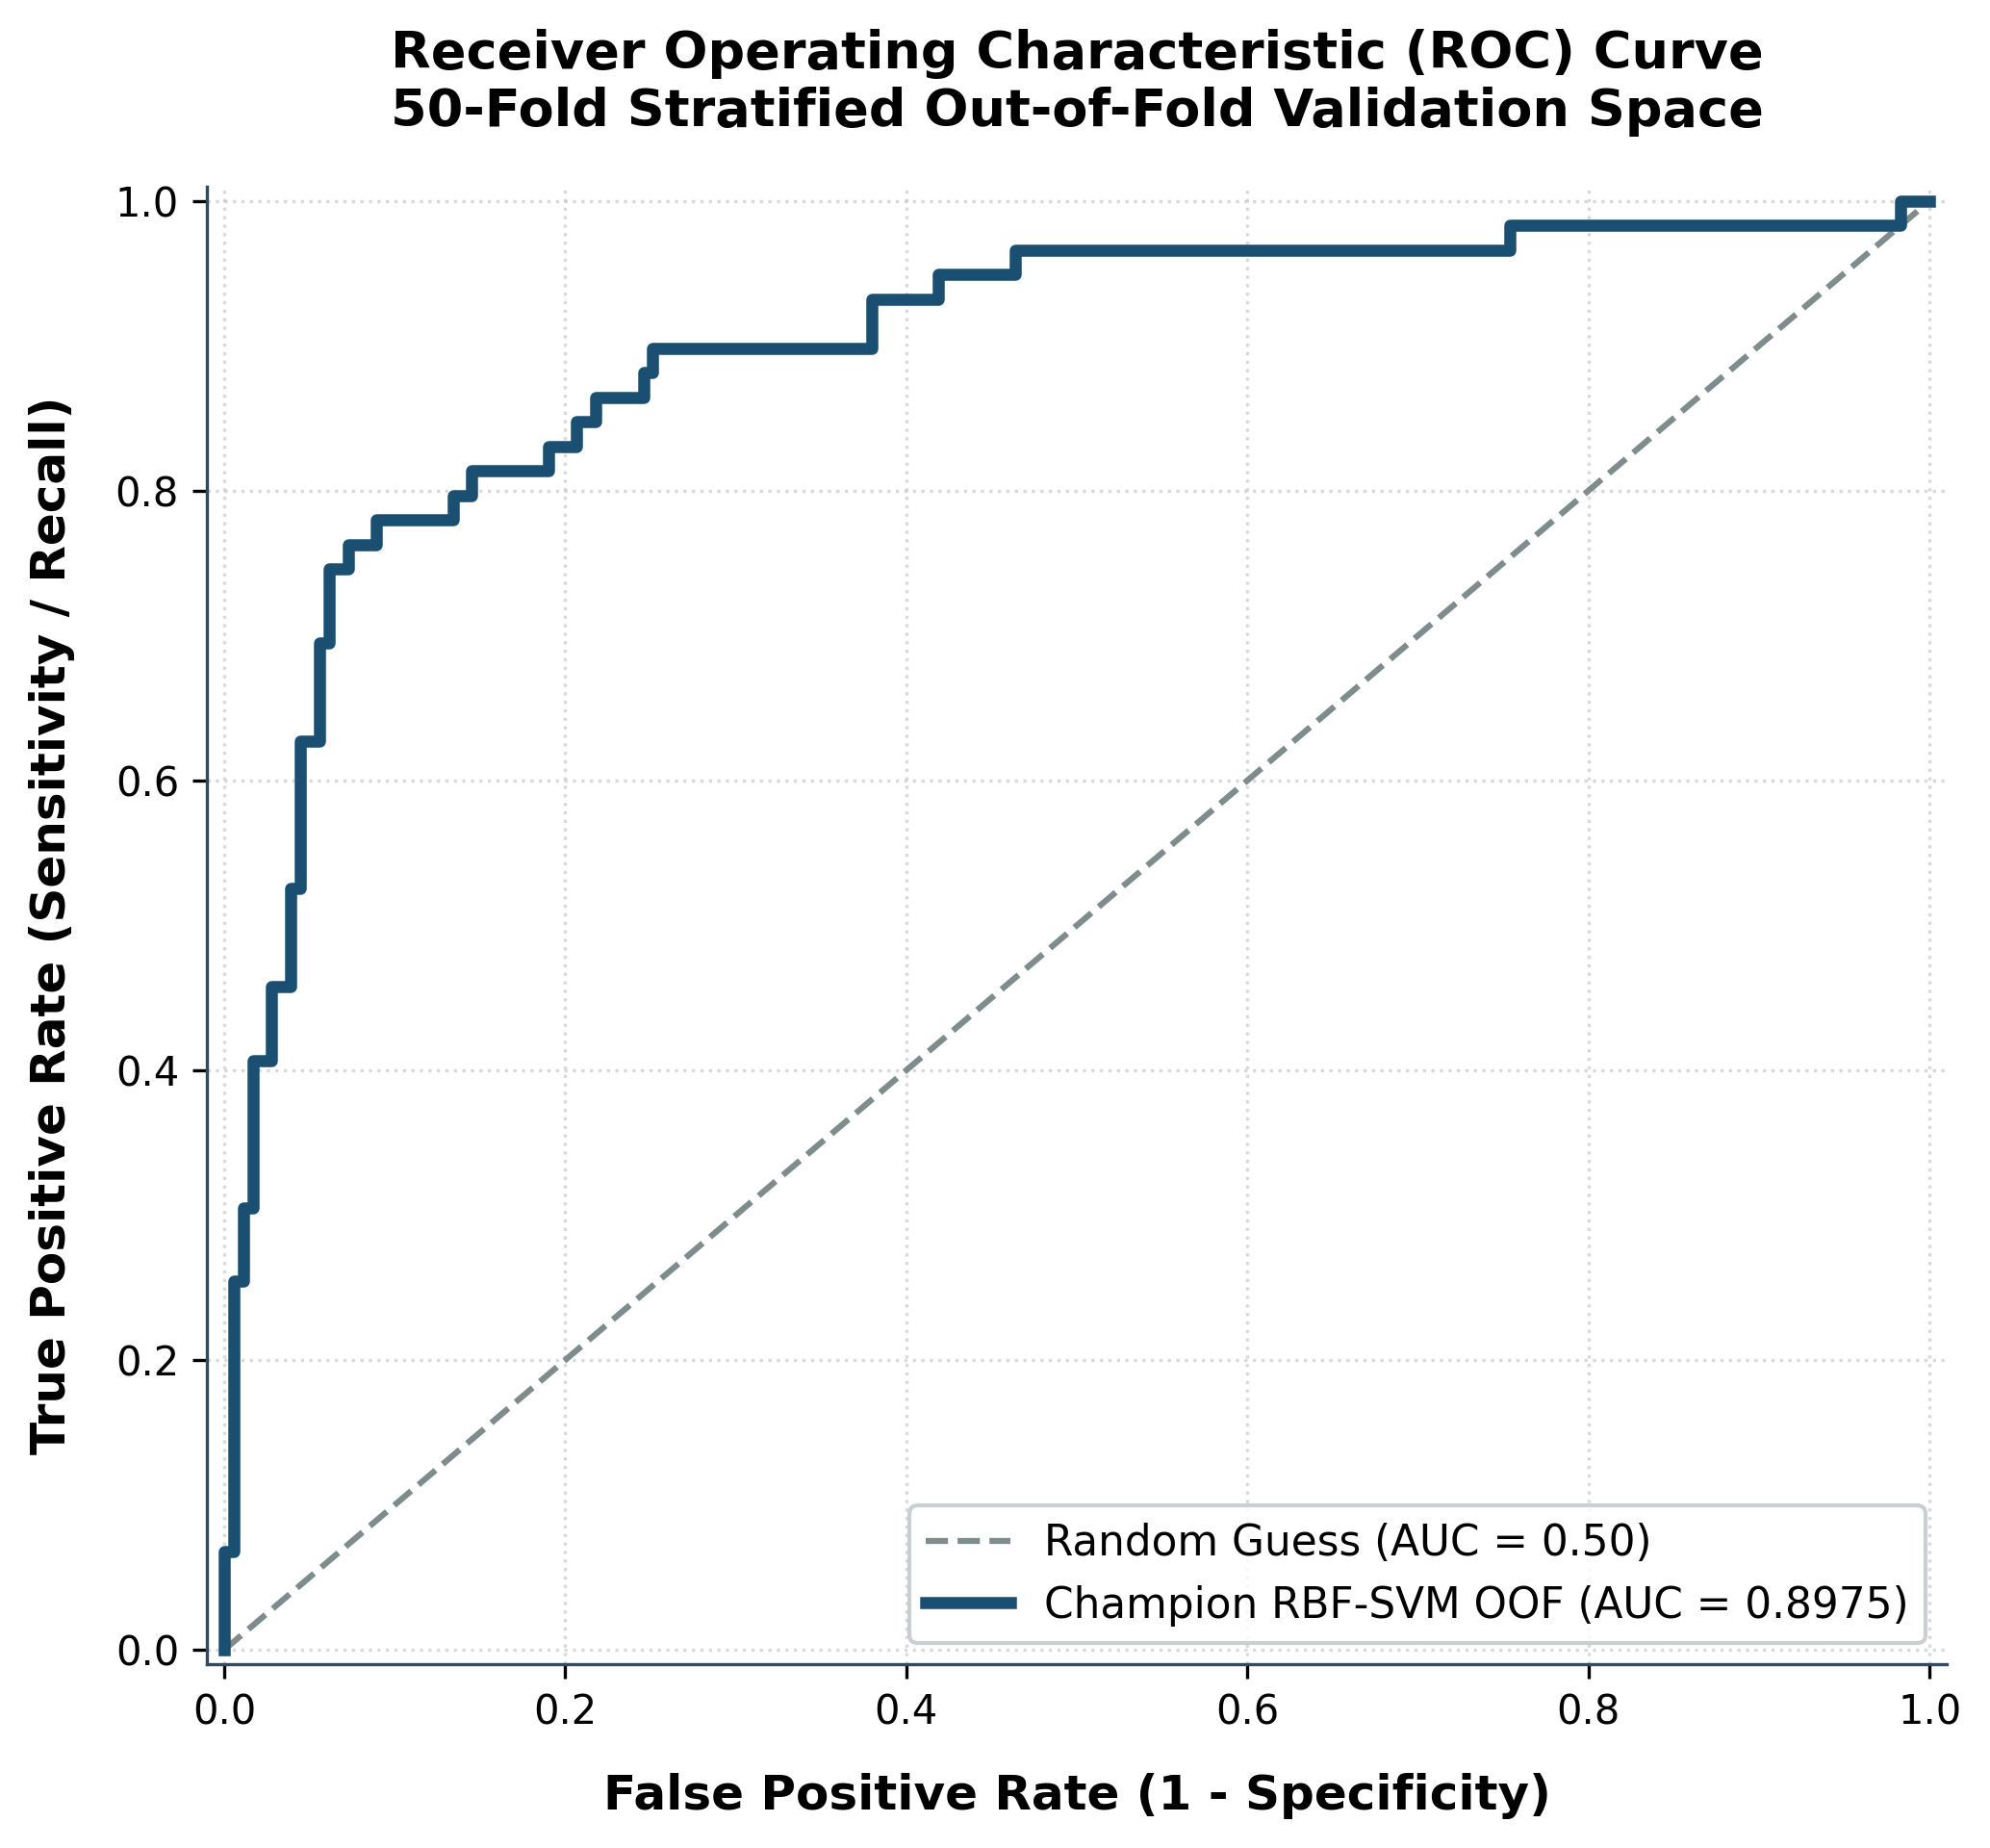

✓ Chart successfully rendered and saved to disk as: 'biomarker_svm_oof_roc_curve.png'


In [25]:
# =====================================================================
# PUBLICATION-READY ROC CURVE GENERATION (50-FOLD OUT-OF-FOLD)
# =====================================================================
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# 1. Compute global False Positive Rate and True Positive Rate from OOF probabilities
fpr, tpr, thresholds = roc_curve(y_all, y_cv_proba)
roc_auc = auc(fpr, tpr)

# 2. Initialize a high-resolution, clean journal layout
plt.figure(figsize=(7, 6.5), dpi=300)

# 3. Plot the Random Chance diagonal line
plt.plot([0, 1], [0, 1], color='#7f8c8d', linestyle='--', linewidth=1.5, label='Random Guess (AUC = 0.50)')

# 4. Plot the Champion SVM OOF ROC Curve
plt.plot(
    fpr,
    tpr,
    color='#1b4f72',   # Deep clinical blue
    linewidth=3,
    label=f'Champion RBF-SVM OOF (AUC = {roc_auc:.4f})'
)

# 5. Aesthetic Adjustments for Peer-Reviewed Standards
plt.xlim([-0.01, 1.01])
plt.ylim([-0.01, 1.01])

plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=12, fontweight='bold', labelpad=10)
plt.title('Receiver Operating Characteristic (ROC) Curve\n50-Fold Stratified Out-of-Fold Validation Space', fontsize=13, fontweight='bold', pad=15)

# Styling the layout elements
plt.grid(True, linestyle=':', alpha=0.6, color='#bdc3c7')
plt.legend(loc='lower right', fontsize=10.5, frameon=True, facecolor='white', edgecolor='#bdc3c7')

# Clean up spine borders
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#34495e')
ax.spines['bottom'].set_color('#34495e')

# 6. Save as an ultra-crisp, print-ready image file
output_image_path = 'biomarker_svm_oof_roc_curve.png'
plt.tight_layout()
plt.savefig(output_image_path, bbox_inches='tight', dpi=300)
plt.show()

print(f"✓ Chart successfully rendered and saved to disk as: '{output_image_path}'")

In [ ]:
# =====================================================================
# END-TO-END CHAMPION RECONSTRUCTION & GOOGLE DRIVE LOCKDOWN
# =====================================================================
import os
import joblib
import numpy as np
import pandas as pd
from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import roc_auc_score

# --- Step 1: Secure the Google Drive Mount ---
print("Connecting to your Google Drive...")
drive.mount('/content/drive')

# !!! CRITICAL REALITY CHECK !!!
# Ensure you have run your data loading code before this cell so 'df' exists.
if 'df' not in locals() and 'df' not in globals():
    raise NameError("The dataset variable 'df' is missing. Please run your cell that imports the data as 'df' first!")

print("\nConfiguring features and re-establishing the train/test splits...")

# --- Step 2: Define Feature Sets & Target ---
target = 'amyloid_label'
raw_features = ['pT217_F', 'AB42_AB40_F', 'GFAP_Q', 'APOE4', 'AGE', 'SEX']

X_raw = df[raw_features].copy()
y = df[target].copy()

# --- Step 3: Re-execute the exact Stratified 80/20 Split ---
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, stratify=y, random_state=42
)

# --- Step 4: Re-define Feature Engineering Function ---
def engineer_hybrid_features(df_input):
    df_out = df_input.copy()
    epsilon = 1e-6
    # Re-create the non-linear biomarker ratio signals
    df_out['GFAP_to_AB_ratio'] = df_out['GFAP_Q'] / (df_out['AB42_AB40_F'] + epsilon)
    df_out['pT217_to_AB_ratio'] = df_out['pT217_F'] / (df_out['AB42_AB40_F'] + epsilon)
    return df_out

X_train_eng = engineer_hybrid_features(X_train_raw)
X_test_eng = engineer_hybrid_features(X_test_raw)

# --- Step 5: Column Group Alignment ---
skewed_cols     = ['pT217_F', 'GFAP_to_AB_ratio', 'pT217_to_AB_ratio']
plain_cols      = ['AB42_AB40_F', 'AGE']
binary_passthru = ['APOE4', 'SEX']

stable_features = skewed_cols + plain_cols + binary_passthru
X_train = X_train_eng[stable_features]
X_test = X_test_eng[stable_features]

# --- Step 6: Re-assemble Champion Preprocessor ---
preprocessor = ColumnTransformer(transformers=[
    ('power_scale', PowerTransformer(method='yeo-johnson', standardize=True), skewed_cols),
    ('scale_only', StandardScaler(), plain_cols),
    ('passthrough', 'passthrough', binary_passthru)
])

# --- Step 7: Instantiate Winning Hyperparameters (C=1.0, gamma=0.05) ---
final_champion_svm = SVC(
    class_weight='balanced',
    kernel='rbf',
    C=1.0,
    gamma=0.05,
    probability=True,
    random_state=42
)

# --- Step 8: Build and Fit Production Pipeline ---
production_pipeline = Pipeline([
    ('preprocess', preprocessor),
    ('clf', final_champion_svm)
])

print("Re-training the 0.9306 configuration from scratch...")
production_pipeline.fit(X_train, y_train)

# --- Step 9: Re-verify Test Performance to guarantee perfect replication ---
final_probs = production_pipeline.predict_proba(X_test)[:, 1]
final_auc = roc_auc_score(y_test, final_probs)
print(f"\n==========================================")
print(f" Re-verified Test ROC-AUC: {final_auc:.4f}")
print(f"==========================================")

# --- Step 10: Serialize Directly to Google Drive ---
drive_folder = '/content/drive/MyDrive/Biomarker_Project/'
model_path = os.path.join(drive_folder, 'amyloid_svm_champion_9306.joblib')

joblib.dump(production_pipeline, model_path)

print("\n=======================================================")
print("✓ PERMANENTLY SECURED IN GOOGLE DRIVE!")
print(f"File Path: {model_path}")
print("=======================================================")

Connecting to your Google Drive...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Configuring features and re-establishing the train/test splits...
Re-training the 0.9306 configuration from scratch...

 Re-verified Test ROC-AUC: 0.9306

✓ PERMANENTLY SECURED IN GOOGLE DRIVE!
File Path: /content/drive/MyDrive/Biomarker_Project/amyloid_svm_champion_9306.joblib


# SVM -> 93 **👆🏼**

In [ ]:
import joblib
# Load the smart pipeline straight from your Drive
loaded_champion = joblib.load('/content/drive/MyDrive/Biomarker_Project/amyloid_svm_champion_9306.joblib')

# Now it's ready to predict new patients instantly:
# predictions = loaded_champion.predict(new_patient_data)